In [2]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
import numpy as np

# Настройка стиля
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# Загрузка данных
df = pd.read_csv('paired_refseq_viral_and_astro_orfs_1_50_batches_results.tsv', sep='\t')
df.head()

D:\Users\User\AppData\Local\Temp\ipykernel_2376\4221050099.py:13: DtypeWarning: Columns (0: Страна) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('paired_refseq_viral_and_astro_orfs_1_50_batches_results.tsv', sep='\t')


,Образец,Страна,Год,Хозяин,"Длина контига, нт",Профиль,"Идентичность, %","Длина выравнивания, амк","Мисматчи, амк",Начало контига,...,Начало референса,Конец референса,"Длина референса, амк","Покрытие контига, %","Покрытие референса, %",E-value,Bit-score,Бласт хит,Инфо,Топ 5 профилей
0,ERR14656582,Spain,2021,feces metagenome,459,Caliciviridae|polyprotein_nonstructural,38.5,143,85,39,...,90,232,1084,91.5,13.2,4.140000e-23,97.4,YP_009507248.1 ORF B [Trichoplusia ni TED virus],Contig_ID: k141_11673 | BioProject: PRJEB76898...,Caliciviridae polyprotein;nonstructural (1.62)...
1,ERR14656582,Spain,2021,feces metagenome,813,Poecivirus|polyprotein,30.8,104,72,634,...,1,104,115,38.4,90.4,1.470000e-11,63.2,YP_009909105.1 transposase [Stx2-converting ph...,Contig_ID: k141_11834 | BioProject: PRJEB76898...,Poecivirus polyprotein (1.21); Megrivirus poly...
2,ERR14656582,Spain,2021,feces metagenome,729,Senecavirus|polyprotein,28.7,136,91,401,...,17,149,239,54.7,55.6,1.800000e-08,56.6,YP_010754570.1 hypothetical protein QEH35_gp10...,Contig_ID: k141_13632 | BioProject: PRJEB76898...,Senecavirus polyprotein (1.04)
3,ERR14656582,Spain,2021,feces metagenome,645,Limnipivirus|polyprotein,34.5,113,73,306,...,1,112,157,52.6,71.3,1.590000e-13,68.6,YP_009174618.1 hypothetical protein AR678_gp16...,Contig_ID: k141_13810 | BioProject: PRJEB76898...,Limnipivirus polyprotein (1.08)
4,ERR14656582,Spain,2021,feces metagenome,1113,Lagovirus|polyprotein_nonstructural,35.5,279,154,836,...,6,259,312,74.9,81.4,5.350000e-41,149.0,YP_009507576.1 asparagine synthetase A [Hetero...,Contig_ID: k141_14129 | BioProject: PRJEB76898...,Lagovirus polyprotein;nonstructural (1.01); Am...


In [3]:
# Функция для определения, является ли запись астровирусом
def is_astrovirus(blast_hit):
    if pd.isna(blast_hit) or str(blast_hit).strip() == "":
        return False
    hit = str(blast_hit).lower()
    astro_patterns = ['astrovirus', 'astroviridae', 'mamastrovirus', 'avastrovirus', 'bastrovirus']
    for pattern in astro_patterns:
        if re.search(pattern, hit, re.IGNORECASE):
            return True
    return False

# Функция для определения источника
def get_source(blast_hit):
    if pd.isna(blast_hit) or str(blast_hit).strip() == "":
        return "Unknown"
    hit = str(blast_hit)
    if re.match(r'^[A-Z]{2}_', hit) or re.match(r'^NP_', hit):
        return "RefSeq Viral"
    else:
        return "GenBank"

# Функция для подсчета ORFs из топ-5 профилей
def analyze_orf_types(top5_profiles):
    """
    Анализирует топ-5 профилей и определяет, какие ORFs астровируса присутствуют
    Возвращает множество найденных ORF типов
    """
    if pd.isna(top5_profiles) or str(top5_profiles).strip() == "":
        return set()
    
    profiles = str(top5_profiles)
    orf_types = set()
    
    # Разбиваем на отдельные профили
    profile_parts = profiles.split(';')
    
    for part in profile_parts:
        part = part.strip()
        
        # Удаляем все, что в скобках (score_ratio)
        part = re.sub(r'\s*\([^)]*\)', '', part)
        
        # Проверяем, что это астровирус
        is_astro = False
        astro_patterns = ['astroviridae', 'astrovirus', 'mamastrovirus', 'avastrovirus', 'bastrovirus']
        for pattern in astro_patterns:
            if re.search(pattern, part, re.IGNORECASE):
                is_astro = True
                break
        
        # Если это не астровирус - пропускаем
        if not is_astro:
            continue
        
        # Проверяем наличие 1A
        if re.search(r'1A\b', part, re.IGNORECASE):
            orf_types.add('1A')
        
        # Проверяем наличие 1B (включая 1b_pcr_primer_region)
        if re.search(r'1B\b', part, re.IGNORECASE) or re.search(r'1b_pcr_primer_region', part, re.IGNORECASE):
            orf_types.add('1B')
        
        # Проверяем наличие ORF2 (только у астровирусов)
        if re.search(r'\b2\b', part) or re.search(r'capsid', part, re.IGNORECASE) or re.search(r'VP90', part):
            orf_types.add('2')
        
        # Проверяем наличие 1ab
        if re.search(r'1ab\b', part, re.IGNORECASE):
            if '1A' not in orf_types and '1B' not in orf_types:
                orf_types.add('1A')
    
    return orf_types

# Применяем функции
df['is_astrovirus'] = df['Бласт хит'].apply(is_astrovirus)
df['source'] = df['Бласт хит'].apply(get_source)
df['orf_types'] = df['Топ 5 профилей'].apply(analyze_orf_types)

# Определяем количество ORFs
df['orf_count'] = df['orf_types'].apply(len)

# Классификация контигов
df['genome_type'] = df['orf_types'].apply(
    lambda x: 'Полный геном (3 ORFs)' if x == {'1A', '1B', '2'} 
    else 'Неполный геном' if x 
    else 'Нет ORFs'
)

# Фильтруем только астровирусы
astro_df = df[df['is_astrovirus'] == True].copy()

print(f"Найдено {len(astro_df)} записей, относящихся к астровирусам")
print(f"Это составляет {len(astro_df)/len(df)*100:.2f}% от всех записей")
print(f"Уникальных образцов с астровирусами: {astro_df['Образец'].nunique()}")

Найдено 1455 записей, относящихся к астровирусам
Это составляет 1.01% от всех записей
Уникальных образцов с астровирусами: 210


In [4]:
astro_df

,Образец,Страна,Год,Хозяин,"Длина контига, нт",Профиль,"Идентичность, %","Длина выравнивания, амк","Мисматчи, амк",Начало контига,...,E-value,Bit-score,Бласт хит,Инфо,Топ 5 профилей,is_astrovirus,source,orf_types,orf_count,genome_type
1077,ERR15951184,United Kingdom,2025,bat gut metagenome,980,Astroviridae|1A,26.3,175,106,143,...,5.210000e-07,54.7,OP589978 ORF1A protein [Bat astrovirus 3],Contig_ID: k141_226857 | BioProject: PRJEB1037...,Astroviridae 1A (1.63); Astroviridae polyprote...,True,GenBank,{1A},1,Неполный геном
1295,ERR15951184,United Kingdom,2025,bat gut metagenome,409,Torchivirus|polyprotein,40.0,40,24,274,...,9.270000e-04,41.2,MG599902 ORF1A protein [Wenling pterygotrigla ...,Contig_ID: k141_67953 | BioProject: PRJEB10376...,Torchivirus polyprotein (1.25); Astroviridae 1...,True,GenBank,{1A},1,Неполный геном
1312,ERR15951184,United Kingdom,2025,bat gut metagenome,301,Torchivirus|polyprotein,48.1,54,27,71,...,3.320000e-04,41.2,OQ802698 ORF1A protein [Jingmen bat astrovirus...,Contig_ID: k141_87154 | BioProject: PRJEB10376...,Torchivirus polyprotein (1.39); Astroviridae 1...,True,GenBank,{1A},1,Неполный геном
2023,ERR15951187,United Kingdom,2025,bat gut metagenome,374,Astroviridae|capsid_VP90,40.0,85,51,116,...,2.610000e-13,68.2,YP_009275018.1 capsid protein [Mamastrovirus 1],Contig_ID: k141_256396 | BioProject: PRJEB1037...,Astroviridae capsid;VP90 (1.25),True,RefSeq Viral,{2},1,Неполный геном
3676,ERR15951190,United Kingdom,2025,bat gut metagenome,2447,Proboscivirus|major,56.3,48,21,1550,...,7.830000e-06,53.1,OL695857 ORF2 protein [Mamastrovirus 3],Contig_ID: k141_148305 | BioProject: PRJEB1037...,Proboscivirus major DNA-binding protein;major ...,True,GenBank,{},0,Нет ORFs
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143277,SRR28250970,Kenya,2015,Mops condylurus,1703,Astroviridae|2,92.0,25,2,1701,...,1.300000e-05,51.6,PQ541169 ORF2 protein [Miniopterus inflatus ba...,Contig_ID: k141_204993 | BioProject: PRJNA1083...,Astroviridae 2 (1.14); Astroviridae 2 (1.02); ...,True,GenBank,{2},1,Неполный геном
143390,SRR28250970,Kenya,2015,Mops condylurus,5855,Astroviridae|2,100.0,1296,0,5854,...,0.000000e+00,2585.0,PP711860 ORF1B protein [Mops bat astrovirus],Contig_ID: k141_94249 | BioProject: PRJNA10837...,Astroviridae 2 (21.86); Astroviridae capsid;VP...,True,GenBank,{2},1,Неполный геном
143393,SRR28250970,Kenya,2015,Mops condylurus,2852,Astroviridae|2,100.0,704,0,2279,...,0.000000e+00,1297.0,PP711866 ORF2 protein [Mops bat astrovirus],Contig_ID: k141_96892 | BioProject: PRJNA10837...,Astroviridae 2 (43.09); Astroviridae capsid;VP...,True,GenBank,"{2, 1B}",2,Неполный геном
143432,SRR5040912,Cameroon,2013,Eidolon helvum,478,Astroviridae|1A,34.6,136,70,401,...,5.700000e-07,51.2,PP711883 ORF1A protein [Aethomys rat astrovirus],Contig_ID: k141_1737 | BioProject: PRJNA344863...,Astroviridae 1A (1.41); Astroviridae polyprote...,True,GenBank,{1A},1,Неполный геном


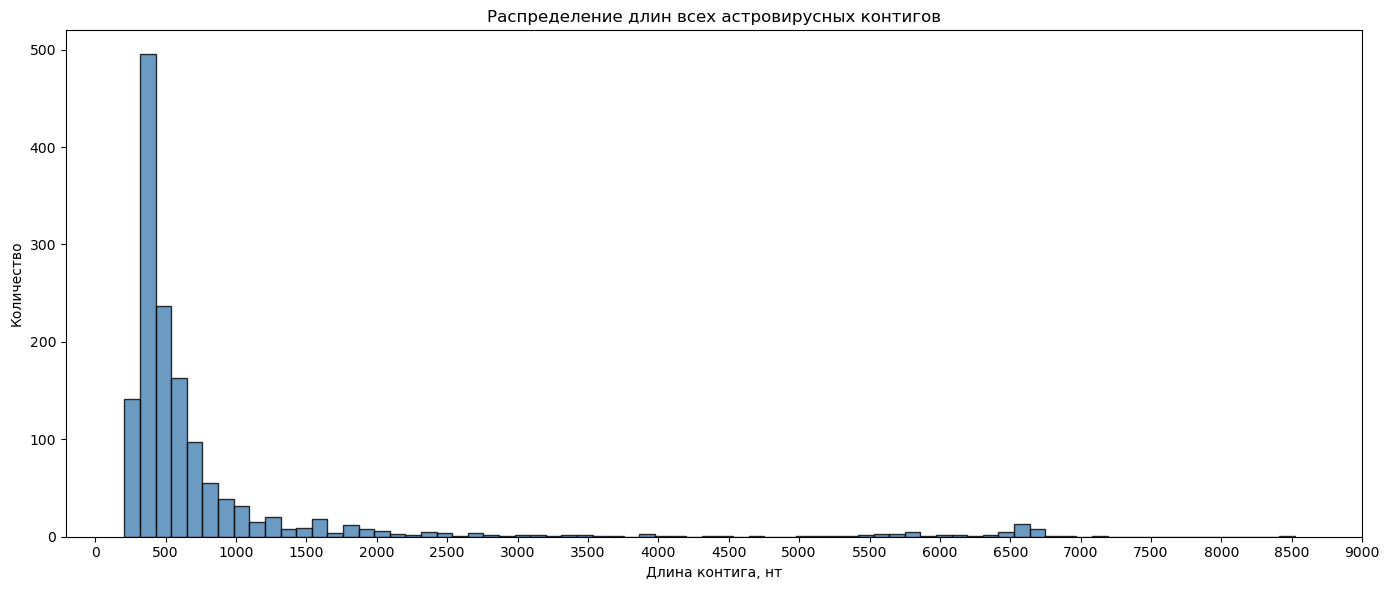

In [29]:
import numpy as np
import matplotlib.pyplot as plt

lengths = astro_df["Длина контига, нт"].dropna().astype(float)

fig, ax = plt.subplots(figsize=(14, 6))
ax.hist(lengths, bins=75, color="steelblue", edgecolor="black", alpha=0.8)
ax.set_title("Распределение длин всех астровирусных контигов")
ax.set_xlabel("Длина контига, нт")
ax.set_ylabel("Количество")

# подписи каждые 500 нт
ax.set_xticks(np.arange(0, lengths.max() + 500, 500))
plt.xticks(rotation=0)  

plt.tight_layout()
plt.show()

In [41]:
mask = astro_df["orf_types"].apply(lambda x: "1B" in x if isinstance(x, set) else False)
astro_df_1B = astro_df[mask].copy()

In [42]:
astro_df_1B

,Образец,Страна,Год,Хозяин,"Длина контига, нт",Профиль,"Идентичность, %","Длина выравнивания, амк","Мисматчи, амк",Начало контига,...,E-value,Bit-score,Бласт хит,Инфо,Топ 5 профилей,is_astrovirus,source,orf_types,orf_count,genome_type
31959,ERR3179229,NaN,2019,viral metagenome,690,Lagovirus|polyprotein_nonstructural,30.5,118,63,478,...,7.310000e-04,43.5,MN832787 ORF1B protein [Bat astrovirus],Contig_ID: k141_48049 | BioProject: PRJEB6505 ...,Lagovirus polyprotein;nonstructural (1.54); La...,True,GenBank,{1B},1,Неполный геном
31971,ERR3179229,NaN,2019,viral metagenome,5651,Astroviridae|1B,74.6,1715,417,412,...,0.000000e+00,2520.0,YP_009552769.1 nonstructural polyprotein [Cule...,Contig_ID: k141_49419 | BioProject: PRJEB6505 ...,Astroviridae 1B (2.11); Norovirus capsid (1.77...,True,RefSeq Viral,{1B},1,Неполный геном
32885,ERR3179231,NaN,2019,viral metagenome,382,Crohivirus|polyprotein,31.3,96,55,52,...,1.100000e-04,43.5,MN832787 ORF1B protein [Bat astrovirus],Contig_ID: k141_26681 | BioProject: PRJEB6505 ...,Crohivirus polyprotein (1.65); Lagovirus polyp...,True,GenBank,{1B},1,Неполный геном
33537,ERR3179232,NaN,2019,viral metagenome,756,Astroviridae|1B,90.6,64,6,53,...,2.650000e-32,126.0,PP871752 ORF1B protein [Mamastrovirus sp.],Contig_ID: k141_127626 | BioProject: PRJEB6505...,Astroviridae 1B (3.08); Mamastrovirus polyprot...,True,GenBank,{1B},1,Неполный геном
34219,ERR3179233,NaN,2019,viral metagenome,402,Astroviridae|1B,38.3,94,56,74,...,1.050000e-07,52.4,MN920668 ORF1B protein [Astroviridae sp.],Contig_ID: k141_15319 | BioProject: PRJEB6505 ...,Astroviridae 1B (2.47); Astroviridae 1b_pcr_pr...,True,GenBank,{1B},1,Неполный геном
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143141,SRR28250944,Kenya,2015,Miniopterus sp. clade 10 TD-2020,6623,Astroviridae|1A,100.0,875,0,2,...,0.000000e+00,1616.0,PP711879 ORF1A protein [Miniopterus bat astrov...,Contig_ID: k141_23310 | BioProject: PRJNA10837...,Astroviridae 1A (52.82); Astroviridae 1B (51.7...,True,GenBank,"{1A, 2, 1B}",3,Полный геном (3 ORFs)
143185,SRR28250970,Kenya,2015,Mops condylurus,929,Astroviridae|1B,67.3,309,101,927,...,2.230000e-161,462.0,OR951045 ORF1B protein [Bat astrovirus],Contig_ID: k141_120728 | BioProject: PRJNA1083...,Astroviridae 1B (33.18); Mamastrovirus polypro...,True,GenBank,{1B},1,Неполный геном
143213,SRR28250970,Kenya,2015,Mops condylurus,6260,Astroviridae|1A,98.8,814,10,6256,...,0.000000e+00,1580.0,PP711858 ORF1A protein [Mops bat astrovirus],Contig_ID: k141_146080 | BioProject: PRJNA1083...,Astroviridae 1A (52.85); Astroviridae 1B (52.8...,True,GenBank,"{1A, 2, 1B}",3,Полный геном (3 ORFs)
143393,SRR28250970,Kenya,2015,Mops condylurus,2852,Astroviridae|2,100.0,704,0,2279,...,0.000000e+00,1297.0,PP711866 ORF2 protein [Mops bat astrovirus],Contig_ID: k141_96892 | BioProject: PRJNA10837...,Astroviridae 2 (43.09); Astroviridae capsid;VP...,True,GenBank,"{2, 1B}",2,Неполный геном


In [49]:
astro_only = astro_df_1B[
    astro_df_1B["Профиль"].astype(str).str.contains(
        "Astroviridae|Mamastrovirus|Avastrovirus",
        case=False, na=False, regex=True
    )
].copy()

In [50]:
astro_only

,Образец,Страна,Год,Хозяин,"Длина контига, нт",Профиль,"Идентичность, %","Длина выравнивания, амк","Мисматчи, амк",Начало контига,...,E-value,Bit-score,Бласт хит,Инфо,Топ 5 профилей,is_astrovirus,source,orf_types,orf_count,genome_type
31971,ERR3179229,NaN,2019,viral metagenome,5651,Astroviridae|1B,74.6,1715,417,412,...,0.000000e+00,2520.0,YP_009552769.1 nonstructural polyprotein [Cule...,Contig_ID: k141_49419 | BioProject: PRJEB6505 ...,Astroviridae 1B (2.11); Norovirus capsid (1.77...,True,RefSeq Viral,{1B},1,Неполный геном
33537,ERR3179232,NaN,2019,viral metagenome,756,Astroviridae|1B,90.6,64,6,53,...,2.650000e-32,126.0,PP871752 ORF1B protein [Mamastrovirus sp.],Contig_ID: k141_127626 | BioProject: PRJEB6505...,Astroviridae 1B (3.08); Mamastrovirus polyprot...,True,GenBank,{1B},1,Неполный геном
34219,ERR3179233,NaN,2019,viral metagenome,402,Astroviridae|1B,38.3,94,56,74,...,1.050000e-07,52.4,MN920668 ORF1B protein [Astroviridae sp.],Contig_ID: k141_15319 | BioProject: PRJEB6505 ...,Astroviridae 1B (2.47); Astroviridae 1b_pcr_pr...,True,GenBank,{1B},1,Неполный геном
35783,ERR3179236,NaN,2019,viral metagenome,576,Astroviridae|2,76.2,147,25,142,...,4.980000e-64,213.0,PX482536 ORF2 protein [Bat astrovirus],Contig_ID: k141_21989 | BioProject: PRJEB6505 ...,Astroviridae 2 (11.33); Astroviridae capsid;VP...,True,GenBank,"{2, 1B}",2,Неполный геном
35851,ERR3179236,NaN,2019,viral metagenome,505,Astroviridae|1B,83.2,167,28,1,...,1.920000e-98,295.0,OR552421 ORF1B protein [Bat astrovirus],Contig_ID: k141_34336 | BioProject: PRJEB6505 ...,Astroviridae 1B (17.78); Mamastrovirus polypro...,True,GenBank,{1B},1,Неполный геном
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143141,SRR28250944,Kenya,2015,Miniopterus sp. clade 10 TD-2020,6623,Astroviridae|1A,100.0,875,0,2,...,0.000000e+00,1616.0,PP711879 ORF1A protein [Miniopterus bat astrov...,Contig_ID: k141_23310 | BioProject: PRJNA10837...,Astroviridae 1A (52.82); Astroviridae 1B (51.7...,True,GenBank,"{1A, 2, 1B}",3,Полный геном (3 ORFs)
143185,SRR28250970,Kenya,2015,Mops condylurus,929,Astroviridae|1B,67.3,309,101,927,...,2.230000e-161,462.0,OR951045 ORF1B protein [Bat astrovirus],Contig_ID: k141_120728 | BioProject: PRJNA1083...,Astroviridae 1B (33.18); Mamastrovirus polypro...,True,GenBank,{1B},1,Неполный геном
143213,SRR28250970,Kenya,2015,Mops condylurus,6260,Astroviridae|1A,98.8,814,10,6256,...,0.000000e+00,1580.0,PP711858 ORF1A protein [Mops bat astrovirus],Contig_ID: k141_146080 | BioProject: PRJNA1083...,Astroviridae 1A (52.85); Astroviridae 1B (52.8...,True,GenBank,"{1A, 2, 1B}",3,Полный геном (3 ORFs)
143393,SRR28250970,Kenya,2015,Mops condylurus,2852,Astroviridae|2,100.0,704,0,2279,...,0.000000e+00,1297.0,PP711866 ORF2 protein [Mops bat astrovirus],Contig_ID: k141_96892 | BioProject: PRJNA10837...,Astroviridae 2 (43.09); Astroviridae capsid;VP...,True,GenBank,"{2, 1B}",2,Неполный геном


In [51]:
ident = pd.to_numeric(astro_only["Идентичность, %"], errors="coerce")
astro_only = astro_only[(ident >= 50)].copy()

In [52]:
astro_only

,Образец,Страна,Год,Хозяин,"Длина контига, нт",Профиль,"Идентичность, %","Длина выравнивания, амк","Мисматчи, амк",Начало контига,...,E-value,Bit-score,Бласт хит,Инфо,Топ 5 профилей,is_astrovirus,source,orf_types,orf_count,genome_type
31971,ERR3179229,NaN,2019,viral metagenome,5651,Astroviridae|1B,74.6,1715,417,412,...,0.000000e+00,2520.0,YP_009552769.1 nonstructural polyprotein [Cule...,Contig_ID: k141_49419 | BioProject: PRJEB6505 ...,Astroviridae 1B (2.11); Norovirus capsid (1.77...,True,RefSeq Viral,{1B},1,Неполный геном
33537,ERR3179232,NaN,2019,viral metagenome,756,Astroviridae|1B,90.6,64,6,53,...,2.650000e-32,126.0,PP871752 ORF1B protein [Mamastrovirus sp.],Contig_ID: k141_127626 | BioProject: PRJEB6505...,Astroviridae 1B (3.08); Mamastrovirus polyprot...,True,GenBank,{1B},1,Неполный геном
35783,ERR3179236,NaN,2019,viral metagenome,576,Astroviridae|2,76.2,147,25,142,...,4.980000e-64,213.0,PX482536 ORF2 protein [Bat astrovirus],Contig_ID: k141_21989 | BioProject: PRJEB6505 ...,Astroviridae 2 (11.33); Astroviridae capsid;VP...,True,GenBank,"{2, 1B}",2,Неполный геном
35851,ERR3179236,NaN,2019,viral metagenome,505,Astroviridae|1B,83.2,167,28,1,...,1.920000e-98,295.0,OR552421 ORF1B protein [Bat astrovirus],Contig_ID: k141_34336 | BioProject: PRJEB6505 ...,Astroviridae 1B (17.78); Mamastrovirus polypro...,True,GenBank,{1B},1,Неполный геном
37905,ERR3179239,NaN,2019,viral metagenome,867,Astroviridae|1B,50.0,266,133,800,...,2.620000e-88,290.0,MZ443626 ORF1B protein [Nelson Astrovirus-like...,Contig_ID: k141_3585 | BioProject: PRJEB6505 |...,Astroviridae 1B (1.39); Limnipivirus polyprote...,True,GenBank,{1B},1,Неполный геном
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143141,SRR28250944,Kenya,2015,Miniopterus sp. clade 10 TD-2020,6623,Astroviridae|1A,100.0,875,0,2,...,0.000000e+00,1616.0,PP711879 ORF1A protein [Miniopterus bat astrov...,Contig_ID: k141_23310 | BioProject: PRJNA10837...,Astroviridae 1A (52.82); Astroviridae 1B (51.7...,True,GenBank,"{1A, 2, 1B}",3,Полный геном (3 ORFs)
143185,SRR28250970,Kenya,2015,Mops condylurus,929,Astroviridae|1B,67.3,309,101,927,...,2.230000e-161,462.0,OR951045 ORF1B protein [Bat astrovirus],Contig_ID: k141_120728 | BioProject: PRJNA1083...,Astroviridae 1B (33.18); Mamastrovirus polypro...,True,GenBank,{1B},1,Неполный геном
143213,SRR28250970,Kenya,2015,Mops condylurus,6260,Astroviridae|1A,98.8,814,10,6256,...,0.000000e+00,1580.0,PP711858 ORF1A protein [Mops bat astrovirus],Contig_ID: k141_146080 | BioProject: PRJNA1083...,Astroviridae 1A (52.85); Astroviridae 1B (52.8...,True,GenBank,"{1A, 2, 1B}",3,Полный геном (3 ORFs)
143393,SRR28250970,Kenya,2015,Mops condylurus,2852,Astroviridae|2,100.0,704,0,2279,...,0.000000e+00,1297.0,PP711866 ORF2 protein [Mops bat astrovirus],Contig_ID: k141_96892 | BioProject: PRJNA10837...,Astroviridae 2 (43.09); Astroviridae capsid;VP...,True,GenBank,"{2, 1B}",2,Неполный геном


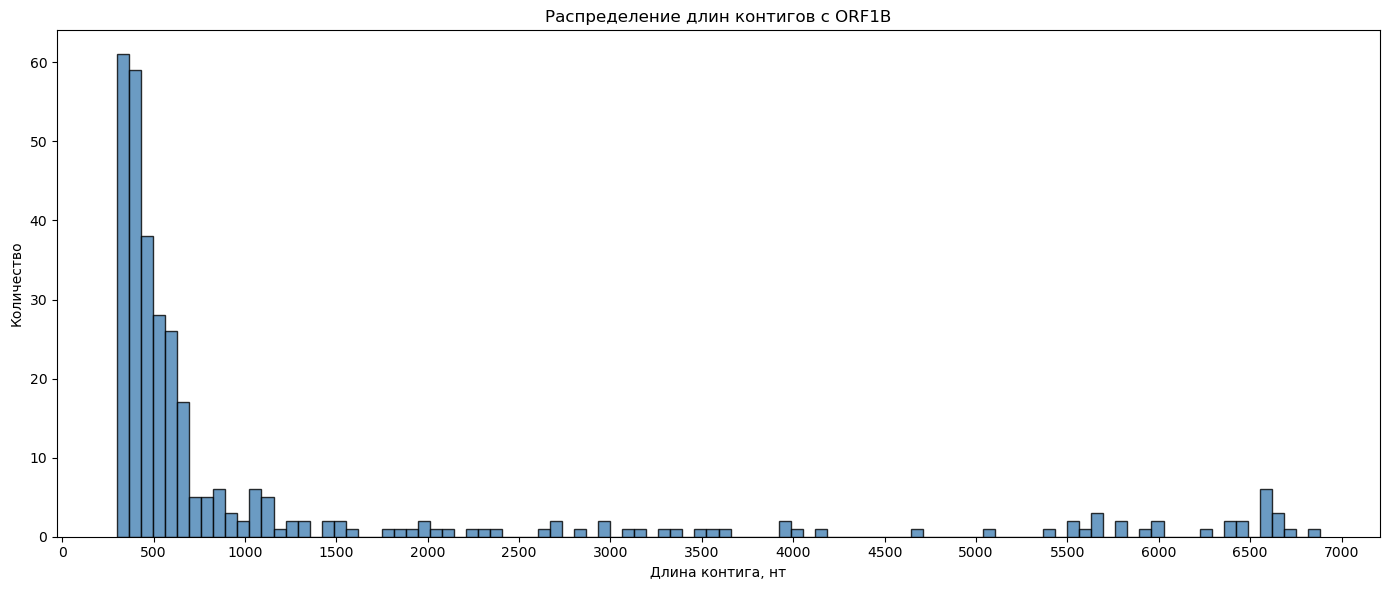

In [38]:
import numpy as np
import matplotlib.pyplot as plt

lengths = astro_only["Длина контига, нт"].dropna().astype(float)

fig, ax = plt.subplots(figsize=(14, 6))
ax.hist(lengths, bins=100, color="steelblue", edgecolor="black", alpha=0.8)
ax.set_title("Распределение длин контигов с ORF1B")
ax.set_xlabel("Длина контига, нт")
ax.set_ylabel("Количество")

# подписи каждые 500 нт
ax.set_xticks(np.arange(0, lengths.max() + 500, 500))
plt.xticks(rotation=0)  

plt.tight_layout()
plt.show()

In [54]:
import re

# astro_only уже есть в окружении
pairs = set()
for _, row in astro_only.iterrows():
    sample = str(row["Образец"]).strip()
    info = str(row["Инфо"])
    m = re.search(r"Contig_ID:\s*(\S+)", info)
    if m:
        pairs.add((sample, m.group(1).strip()))

print(f"Пар (образец, contig) в таблице: {len(pairs)}")

# ---------- Фильтрация FASTA ----------
fasta_in = "all_calculated_contigs_from_best_blast_hits_table.fasta"
fasta_out = "astro_only_filtered.fasta"

kept = 0
total = 0
found_pairs = set()

with open(fasta_in, encoding='utf-8') as fin, open(fasta_out, 'w', encoding='utf-8') as fout:
    write_record = False
    for line in fin:
        if line.startswith(">"):
            total += 1
            header = line[1:].strip()
            first_part = header.split("/", 1)[0]      # ERR3179232|k141_127626
            parts = first_part.split("|")
            if len(parts) >= 2:
                key = (parts[0], parts[1])             # (образец, contig)
                if key in pairs:
                    write_record = True
                    kept += 1
                    found_pairs.add(key)
                    fout.write(line)
                else:
                    write_record = False
            else:
                write_record = False
        else:
            if write_record:
                fout.write(line)

print(f"Всего записей в FASTA: {total}")
print(f"Оставлено: {kept}")

# ---------- Диагностика: какие пары не нашлись ----------
missing = pairs - found_pairs
if missing:
    print(f"\nНе нашлось в FASTA пар: {len(missing)}")
    for s, c in list(missing)[:20]:
        print(f"  {s} | {c}")
else:
    print("\nВсе пары из таблицы найдены в FASTA.")

Пар (образец, contig) в таблице: 364
Всего записей в FASTA: 148964
Оставлено: 364

Все пары из таблицы найдены в FASTA.


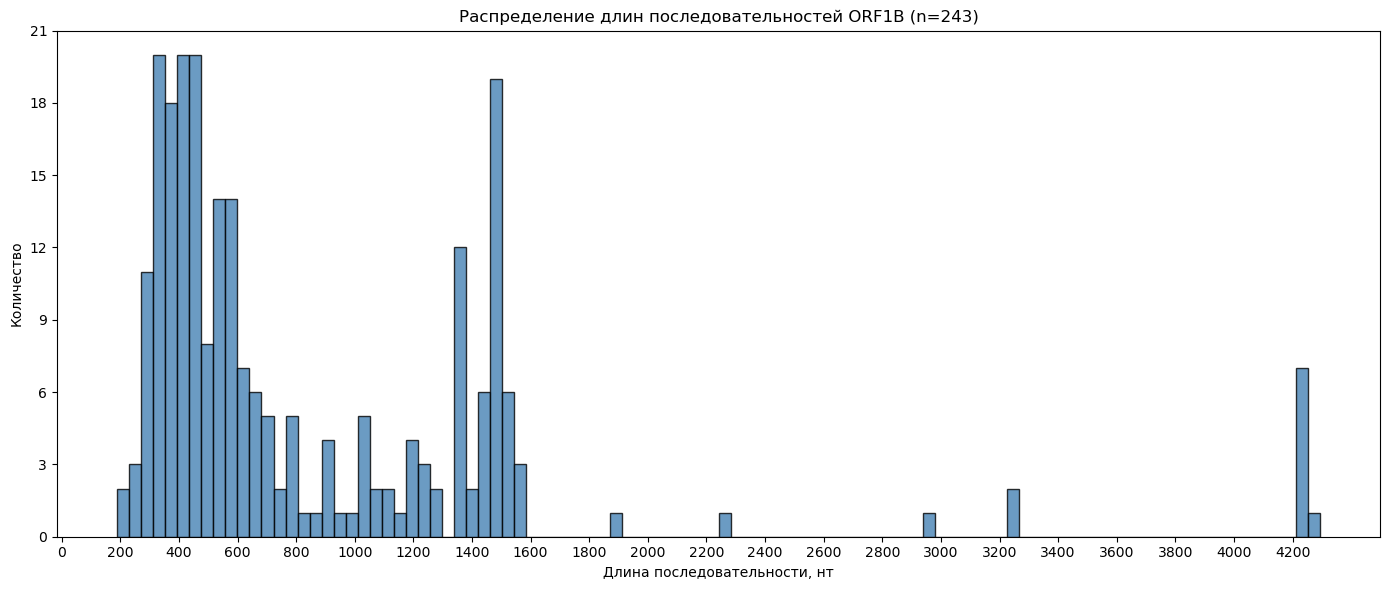

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import MaxNLocator



def fasta_lengths(path):
    lengths, n = [], 0
    with open(path) as fh:
        for line in fh:
            if line.startswith(">"):
                if n: lengths.append(n)
                n = 0
            else:
                n += len(line.strip())
    if n: lengths.append(n)
    return lengths

path = "orfs_1B.fna"
lengths = np.array(fasta_lengths(path), dtype=float)

fig, ax = plt.subplots(figsize=(14, 6))
ax.hist(lengths, bins=100, color="steelblue", edgecolor="black", alpha=0.8)
ax.set_title(f"Распределение длин последовательностей ORF1B "
             f"(n={len(lengths)})")
ax.set_xlabel("Длина последовательности, нт")
ax.set_ylabel("Количество")

ax.set_xticks(np.arange(0, lengths.max() + 100, 200))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()